# ML Network Intrusion Detector
Scikit-learn models that classify network connections as **normal / attack** (binary) and by **attack family** (normal, DoS, Probe, R2L, U2R) on the public **NSL-KDD** dataset.

Train: `KDDTrain+` · Test: `KDDTest+` (contains attack types unseen in training).

## 1. Setup

In [1]:
from pathlib import Path
import urllib.request, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

## 2. Load data (auto-downloads NSL-KDD from GitHub)

In [2]:
BASE = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
FILES = {"train": "KDDTrain+.txt", "test": "KDDTest+.txt"}

COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment",
 "urgent","hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted",
 "num_root","num_file_creations","num_shells","num_access_files","num_outbound_cmds",
 "is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
 "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate",
 "dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
 "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
 "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]
CATEGORICAL = ["protocol_type", "service", "flag"]
DROP = ["label", "attack_class", "is_attack"]

ATTACK_MAP = {"normal": "normal",
 **dict.fromkeys(["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm",
                  "processtable","worm","mailbomb"], "dos"),
 **dict.fromkeys(["satan","ipsweep","nmap","portsweep","mscan","saint"], "probe"),
 **dict.fromkeys(["guess_passwd","ftp_write","imap","phf","multihop","warezmaster","warezclient",
                  "spy","xlock","xsnoop","snmpguess","snmpgetattack","httptunnel","sendmail","named"], "r2l"),
 **dict.fromkeys(["buffer_overflow","loadmodule","rootkit","perl","sqlattack","xterm","ps"], "u2r")}

def load(split):
    p = DATA_DIR / FILES[split]
    if not p.exists():
        urllib.request.urlretrieve(BASE + FILES[split], p)
    df = pd.read_csv(p, header=None, names=COLS).drop(columns="difficulty")
    df["attack_class"] = df["label"].map(ATTACK_MAP)
    assert df["attack_class"].notna().all()
    df["is_attack"] = (df["label"] != "normal").astype(int)
    return df

tr, te = load("train"), load("test")
Xtr, Xte = tr.drop(columns=DROP), te.drop(columns=DROP)
print("train", tr.shape, "| test", te.shape)
print("missing values:", int(tr.isna().sum().sum() + te.isna().sum().sum()))

train (125973, 44) | test (22544, 44)
missing values: 0


## 3. Quick EDA

,train,test
attack_class,,
dos,45927,7460
normal,67343,9711
probe,11656,2421
r2l,995,2885
u2r,52,67


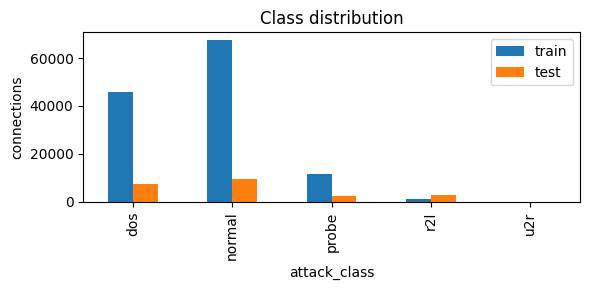

Attack labels in test but not in train: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [3]:
dist = pd.DataFrame({"train": tr.attack_class.value_counts(), "test": te.attack_class.value_counts()})
display(dist)
ax = dist.plot.bar(figsize=(6, 3), title="Class distribution"); ax.set_ylabel("connections"); plt.tight_layout(); plt.show()
print("Attack labels in test but not in train:", sorted(set(te.label) - set(tr.label)))

## 4. Preprocessing + models

In [4]:
def make_pre():
    num = [c for c in Xtr.columns if c not in CATEGORICAL]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])

def models():
    return {
        "logreg": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        "random_forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED,
                                                class_weight="balanced_subsample"),
        "hist_gb": HistGradientBoostingClassifier(random_state=SEED)}

## 5. Binary detection (normal vs attack)

In [5]:
results, fitted = {}, {}
for name, clf in models().items():
    pipe = Pipeline([("pre", make_pre()), ("clf", clf)])
    t = time.time(); pipe.fit(Xtr, tr.is_attack); dt = time.time() - t
    pred, score = pipe.predict(Xte), pipe.predict_proba(Xte)[:, 1]
    results[name] = dict(accuracy=accuracy_score(te.is_attack, pred),
                         precision=precision_score(te.is_attack, pred),
                         recall=recall_score(te.is_attack, pred),
                         f1=f1_score(te.is_attack, pred),
                         roc_auc=roc_auc_score(te.is_attack, score), fit_seconds=dt)
    fitted[name] = pipe
res = pd.DataFrame(results).T.round(4)
display(res)
best = res.f1.idxmax()
print("Best by F1:", best)

,accuracy,precision,recall,f1,roc_auc,fit_seconds
logreg,0.7547,0.9170,0.6257,0.7439,0.7912,3.2590
random_forest,0.7685,0.9678,0.6137,0.7511,0.9595,21.3668
hist_gb,0.8082,0.9696,0.6845,0.8025,0.9602,10.0345


Best by F1: hist_gb


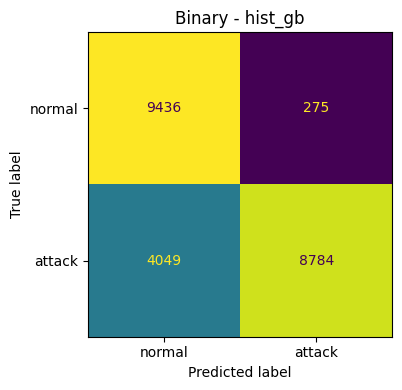

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(te.is_attack, fitted[best].predict(Xte),
    display_labels=["normal", "attack"], ax=ax, colorbar=False)
ax.set_title(f"Binary - {best}"); plt.tight_layout(); plt.show()

### In-distribution sanity check
5-fold CV on `KDDTrain+` only. A large gap vs. `KDDTest+` indicates distribution shift (novel attacks), not leakage or a bug.

In [7]:
cv = cross_val_score(Pipeline([("pre", make_pre()), ("clf", models()[best])]), Xtr, tr.is_attack,
                     scoring="f1", n_jobs=-1, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
print("CV F1:", cv.round(4), "mean", cv.mean().round(4))

CV F1: [0.999  0.9988 0.9987 0.999  0.999 ] mean 0.9989


## 6. Multiclass (attack family)

              precision    recall  f1-score   support

         dos     0.9634    0.8358    0.8951      7460
      normal     0.7106    0.9701    0.8203      9711
       probe     0.7610    0.6299    0.6893      2421
         r2l     0.9104    0.2007    0.3289      2885
         u2r     0.0632    0.1642    0.0913        67

    accuracy                         0.7883     22544
   macro avg     0.6817    0.5601    0.5650     22544
weighted avg     0.8233    0.7883    0.7659     22544



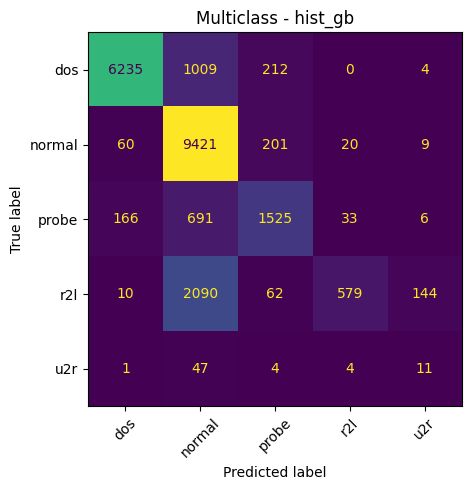

In [8]:
mc = Pipeline([("pre", make_pre()), ("clf", models()[best])]).fit(Xtr, tr.attack_class)
pm = mc.predict(Xte)
print(classification_report(te.attack_class, pm, digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(te.attack_class, pm, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f"Multiclass - {best}"); plt.tight_layout(); plt.show()

## 7. Feature importance (permutation, binary model)

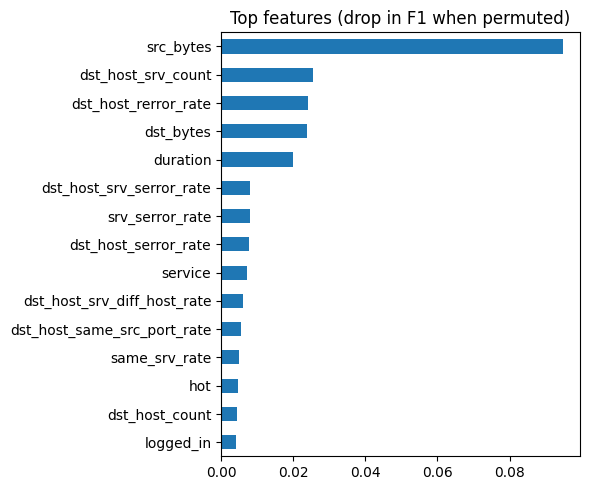

,importance
src_bytes,0.0948
dst_host_srv_count,0.0254
dst_host_rerror_rate,0.0241
dst_bytes,0.0237
duration,0.0198
dst_host_srv_serror_rate,0.0081
srv_serror_rate,0.0080
dst_host_serror_rate,0.0079
service,0.0073
dst_host_srv_diff_host_rate,0.0061


In [9]:
sub = Xte.sample(3000, random_state=SEED)
pi = permutation_importance(fitted[best], sub, te.is_attack.loc[sub.index], scoring="f1",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot.barh(figsize=(6, 5), title="Top features (drop in F1 when permuted)")
plt.tight_layout(); plt.show()
display(imp.head(10).round(4).to_frame("importance"))

## 8. Save models + inference helper

In [10]:
joblib.dump(fitted[best], MODEL_DIR / "binary_detector.joblib")
joblib.dump(mc, MODEL_DIR / "multiclass_detector.joblib")

def detect(df_features, multiclass=False):
    """df_features: DataFrame with the 41 NSL-KDD feature columns."""
    m = joblib.load(MODEL_DIR / ("multiclass_detector.joblib" if multiclass else "binary_detector.joblib"))
    out = pd.DataFrame({"prediction": m.predict(df_features)}, index=df_features.index)
    if not multiclass:
        out["attack_prob"] = m.predict_proba(df_features)[:, 1].round(4)
    return out

sample = Xte.head(5)
display(pd.concat([detect(sample), detect(sample, True).rename(columns={"prediction": "family"}),
                   te[["label"]].head(5)], axis=1))

,prediction,attack_prob,family,label
0,1,1.0000,dos,neptune
1,1,1.0000,dos,neptune
2,0,0.0011,normal,normal
3,1,0.9987,probe,saint
4,0,0.0437,normal,mscan


## Notes
- R2L/U2R recall is low: rare in training, novel in test. Next: cost-sensitive tuning/SMOTE, IsolationForest hybrid, UNSW-NB15 / CIC-IDS2017.
- NSL-KDD is dated; treat it as a benchmark, not a production signal.